In [1]:
import pathlib
import sys

from matplotlib import pyplot as plt

# the analysis code lives in epg_silencing_analysis.py next to this notebook
# (run it as a script to regenerate everything: python epg_silencing_analysis.py)
sys.path.insert(0, str(pathlib.Path.cwd()))
import epg_silencing_analysis as es

plt.rcParams['pdf.fonttype'] = 42

%load_ext autoreload
%autoreload 2
%matplotlib inline

In [2]:
sess_manager = es.load_session_manager()     # folders: see es.BASEDIR, es.DEFAULT_FIGDIR
sess_manager.sess_df.head()

,date,fly,session,fictrac_scan_num,fictrac_file,condition,scan_type,usable,notes,fly_id
0,06_08_2026,fly1,baseline-001,1,fictrac-20260806_092051.dat,exp,baseline,1,NaN,06_08_2026_fly1_condition_exp
1,06_08_2026,fly1,post_heat-002,2,fictrac-20260806_092051.dat,exp,post_heat,1,NaN,06_08_2026_fly1_condition_exp
2,06_08_2026,fly2,baseline-000,0,fictrac-20260806_103458.dat,exp,baseline,1,NaN,06_08_2026_fly2_condition_exp
3,06_08_2026,fly2,post_heat-002,2,fictrac-20260806_103458.dat,exp,post_heat,1,NaN,06_08_2026_fly2_condition_exp
4,06_08_2026,fly5,baseline-000,0,fictrac-20260806_140412.dat,exp,baseline,1,NaN,06_08_2026_fly5_condition_exp


## PV magnitude vs rotation speed, 25 C vs 33 C

In [3]:
grouped = es.compute_binned_stats(sess_manager)
grouped.head()

,fly_id,scan_type,condition,rho_dig,rho_mean
0,06_08_2026_fly1_condition_exp,baseline,exp,"[0.26979907617492116, 0.6892507229677365, 0.68...",0.788413
1,06_08_2026_fly1_condition_exp,post_heat,exp,"[0.14969234380188365, 0.14393620649602823, 0.1...",0.149846
2,06_08_2026_fly1_condition_gal4_only,baseline,gal4_only,"[0.2207493403791772, 0.29411099551809095, 0.30...",0.383609
3,06_08_2026_fly1_condition_gal4_only,post_heat,gal4_only,"[0.3246710276520061, 0.3505596647803977, 0.384...",0.325076
4,06_08_2026_fly2_condition_exp,baseline,exp,"[0.180450301535101, 0.37438453568707547, 0.435...",0.588928


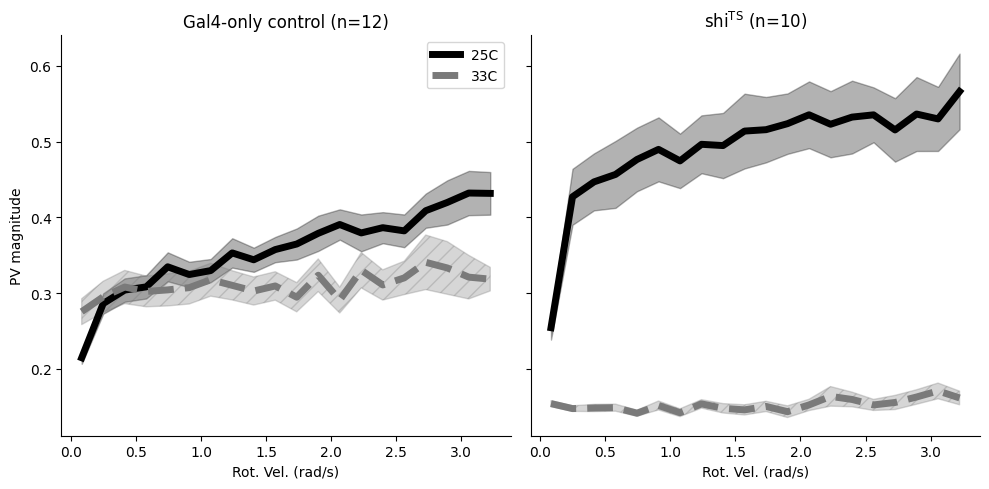

In [4]:
fig = es.plot_rho_vs_speed(sess_manager, grouped)

## Mean PV magnitude per fly

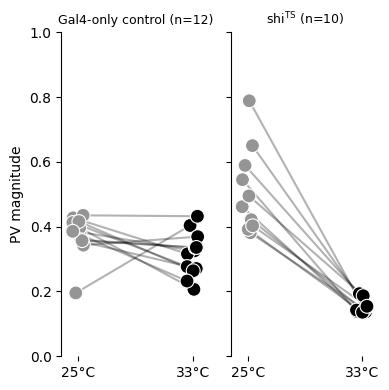

In [5]:
fig = es.plot_rho_mean(sess_manager, grouped)

In [6]:
# mixed ANOVA (condition x temperature) and non-parametric follow-up tests of the interaction
tables = es.rho_mean_tests(grouped)
for name, table in tables.items():
    print(name)
    display(table)

rho_mean_mixed_anova


,Source,SS,DF1,DF2,MS,F,p_unc,np2,eps
0,condition,0.001111,1,20,0.001111,0.190443,6.672229e-01,0.009432,NaN
1,scan_type,0.418563,1,20,0.418563,60.471811,1.801298e-07,0.751466,1.0
2,Interaction,0.247432,1,20,0.247432,35.747726,7.586580e-06,0.641241,NaN


rho_mean_pairwise_heat_effect


,Contrast,condition,A,B,Paired,Parametric,U_val,W_val,alternative,p_unc,p_corr,p_adjust,hedges
0,condition,-,exp,gal4_only,False,False,46.0,NaN,two-sided,0.373378,NaN,NaN,-0.179759
1,scan_type,-,baseline,post_heat,True,False,NaN,16.0,two-sided,0.000081,NaN,NaN,1.749386
2,condition * scan_type,exp,baseline,post_heat,True,False,NaN,0.0,two-sided,0.001953,0.003906,holm,3.642202
3,condition * scan_type,gal4_only,baseline,post_heat,True,False,NaN,16.0,two-sided,0.077148,0.077148,holm,0.857455


rho_mean_pairwise_condition_effect


,Contrast,scan_type,A,B,Paired,Parametric,U_val,W_val,alternative,p_unc,p_corr,p_adjust,hedges
0,scan_type,-,baseline,post_heat,True,False,NaN,16.0,two-sided,0.000081,NaN,NaN,1.749386
1,condition,-,exp,gal4_only,False,False,46.0,NaN,two-sided,0.373378,NaN,NaN,-0.179759
2,scan_type * condition,baseline,exp,gal4_only,False,False,102.0,NaN,two-sided,0.006211,0.006211,holm,1.347534
3,scan_type * condition,post_heat,exp,gal4_only,False,False,0.0,NaN,two-sided,0.000087,0.000175,holm,-2.980198


rho_mean_interaction_contrasts


,Contrast,condition,A,B,Paired,Parametric,U_val,W_val,alternative,p_unc,p_corr,p_adjust,hedges,family,scan_type,p_bonferroni,reject
0,condition * scan_type,exp,baseline,post_heat,True,False,NaN,0.0,two-sided,0.001953,0.003906,holm,3.642202,heat effect within condition,NaN,0.007812,True
1,condition * scan_type,gal4_only,baseline,post_heat,True,False,NaN,16.0,two-sided,0.077148,0.077148,holm,0.857455,heat effect within condition,NaN,0.308594,False
2,scan_type * condition,NaN,exp,gal4_only,False,False,102.0,NaN,two-sided,0.006211,0.006211,holm,1.347534,condition effect within temperature,baseline,0.024844,True
3,scan_type * condition,NaN,exp,gal4_only,False,False,0.0,NaN,two-sided,0.000087,0.000175,holm,-2.980198,condition effect within temperature,post_heat,0.000349,True


## Session heatmaps (baseline and post-heat) with offset histograms

In [7]:
plotted_flies = es.plot_session_figures(sess_manager)
len(plotted_flies)

22